# 03 · Main experiment: checks and PSE vs. conflict

1. **Design:** trials per block, condition and presentation order. Order must be balanced exactly.
2. **Timing:**
   - Logged visual durations should match the intended ones.
   - Each visual flash should be centred on its own sound (v1 displaced the second interval).
   - Watch for dropped frames, frame-0 flip error and audio scheduling.
3. **PSE vs. conflict:** per participant, noise level and conflict, with low and high noise in separate panels.
4. **Interval bias:** PSE for test-first vs. test-second trials. Balanced order keeps this out of the pooled PSE.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
ROOT = Path.cwd().resolve().parent                      # av_dur_experiment_v2/
sys.path[:0] = [str(ROOT), str(ROOT.parent)]            # experiment code + repository (plot_style.py)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
try:
    from plot_style import *                            # shared figure style of the repository
except ImportError:
    FONT_SIZE_LABEL, FONT_SIZE_TITLE = 14, 16
    def add_panel_labels(*a, **k): pass

import experiment_settings as S
from avdur import storage, psychometrics as pm, bias as bias_mod

DATA_ROOT = ROOT / 'data_solid'           # complete sessions of real participants (copied there automatically)
# DATA_ROOT = ROOT / 'data'               # every real run as recorded, including stopped sessions
# DATA_ROOT = ROOT / 'data_test'          # test-display runs and autotests
if not storage.sessions(root=DATA_ROOT):      # no session there yet
    DATA_ROOT = ROOT / 'data_simulated'
    print('No sessions in data_solid/ yet: showing SIMULATED participants (python tests/test_pipeline.py).')
print('Data folder:', DATA_ROOT, '| participants:', storage.participants(DATA_ROOT))

No sessions in data_solid/ yet: showing SIMULATED participants (python tests/test_pipeline.py).
Data folder: /Users/ofy204/Documents/my_repos/av-dur-estimation/av_dur_experiment_v2/data_simulated | participants: ['SIM01', 'SIM02', 'SIM75']


In [2]:
def binned(df, x_col='x', n_bins=8):
    d = df.copy()
    d['bin'] = pd.qcut(d[x_col], n_bins, duplicates='drop')
    return d.groupby('bin', observed=True).agg(x=(x_col, 'mean'), p=('chose_test', 'mean'), n=('chose_test', 'size'))

def order_balance(df, keys):
    t = df.groupby(keys + ['order']).size().unstack(fill_value=0)
    t['test-second share'] = (t.get(2, 0) / t.sum(axis=1)).round(2)
    return t

In [3]:
m = storage.load_trials('main', root=DATA_ROOT)
m['conflict_ms'] = (1000 * m.conflict_nominal).round().astype(int)
print(f'{len(m)} main-experiment trials from {m.participantID.nunique()} participants')
counts = m.groupby(['participantID', 'block', 'audNoise', 'conflict_ms', 'order']).size().unstack('order')
counts['imbalance'] = (counts[1] - counts[2]).abs()
print('largest test-first / test-second imbalance in any cell:', int(counts.imbalance.max()))
counts.head(14)

4312 main-experiment trials from 2 participants
largest test-first / test-second imbalance in any cell: 0


order                                      1   2  imbalance
participantID block audNoise conflict_ms                   
SIM01         B1    0.1      -167         77  77          0
                              0           77  77          0
                              250         77  77          0
                    1.2      -167         77  77          0
                              0           77  77          0
                              250         77  77          0
              B2    0.1      -83          77  77          0
                              167         77  77          0
                    1.2      -83          77  77          0
                              167         77  77          0
              B3    0.1      -250         77  77          0
                              83          77  77          0
                    1.2      -250         77  77          0
                              83          77  77          0

## Timing checks

In [4]:
def frames(col):
    return m[col].str.split('-', expand=True).astype(float)

timing = pd.DataFrame({'participant': m.participantID, 'order': m.order})
for k in (1, 2):
    a, v = frames(f'audio_interval{k}'), frames(f'visual_interval{k}')
    timing[f'centre_offset_interval{k}_ms'] = 1000 * ((v[0] + v[1]) / 2 - (a[0] + a[1]) / 2) / m.frame_rate_hz
timing['test_dur_error_ms'] = 1000 * (m.recordedDurVisualTest - m.intendedDurVisualTest)
timing['standard_dur_error_ms'] = 1000 * (m.recordedDurVisualStandard - m.intendedDurVisualStandard)
timing['dropped_frames'] = m.n_dropped_frames
timing['flip0_error_ms'] = 1000 * m.flip0_error_s
timing['sound_onset_minus_flip0_ms'] = 1000 * m.audio_start_minus_flip0_s   # PTB's estimate
timing.groupby(['participant', 'order']).agg(['median', 'max']).round(1)

centre_offset_interval1_ms      centre_offset_interval2_ms  \
                                      median  max                     median   
participant order                                                              
SIM01       1                            2.1  4.2                        0.0   
            2                            0.0  4.2                        2.1   
SIM02       1                            0.0  4.2                        0.0   
            2                            0.0  4.2                        0.0   

                       test_dur_error_ms      standard_dur_error_ms       \
                   max            median  max                median  max   
participant order                                                          
SIM01       1      4.2              -0.0  1.5                  -0.0  1.2   
            2      4.2              -0.0  1.3                  -0.0  1.5   
SIM02       1      4.2              -0.0  1.5                  -0.0  1.3   
            2      4.2              -0.0  1.2                   0.0  1.5   

                  dropped_frames     flip0_error_ms       \
                          median max         median  max   
participant order                                          
SIM01       1                0.0   0            0.0  0.0   
            2                0.0   0            0.0  0.0   
SIM02       1                0.0   0            0.0  0.0   
            2                0.0   0            0.0  0.0   

                  sound_onset_minus_flip0_ms       
                                      median  max  
participant order                                  
SIM01       1                            0.0  0.7  
            2                            0.0  0.6  
SIM02       1                            0.0  0.7  
            2                           -0.0  0.6

## PSE vs. conflict

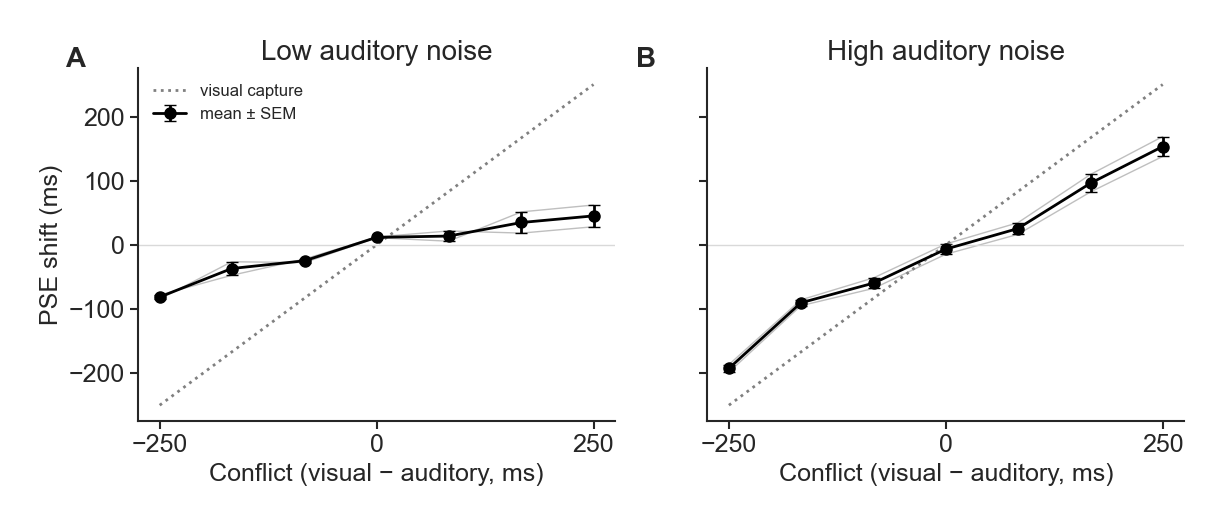

In [5]:
cells = []
for (pid, noise), d in m.groupby(['participantID', 'audNoise']):
    fit = pm.fit(d, 'conflict_ms', 'lognormal', lapse_max=0.25)['params']
    for _, r in fit.iterrows():
        cells.append(dict(participant=pid, noise=noise, conflict_ms=r.condition,
                          pse_ms=1000 * S.STANDARD_DUR_S * (np.exp(r.mu) - 1), sigma=r.sigma, n=r.n))
pse = pd.DataFrame(cells)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, noise, title in zip(axes, S.NOISE_LEVELS, ['Low auditory noise', 'High auditory noise']):
    d = pse[pse.noise == noise]
    for pid, g in d.groupby('participant'):
        ax.plot(g.conflict_ms, g.pse_ms, '-', color='0.75', lw=1)
    grp = d.groupby('conflict_ms').pse_ms.agg(['mean', 'sem']).reset_index()
    ax.errorbar(grp.conflict_ms, grp['mean'], yerr=grp['sem'].fillna(0), fmt='o-', color='black', capsize=4,
                label='mean ± SEM')
    ax.plot([-250, 250], [-250, 250], ':', color='0.5', label='visual capture')
    ax.axhline(0, color='0.85', lw=1)
    ax.set(title=title, xlabel='Conflict (visual − auditory, ms)', xticks=[-250, 0, 250])
    sns.despine(ax=ax)
axes[0].set_ylabel('PSE shift (ms)')
axes[0].legend(frameon=False, fontsize=12)
add_panel_labels(axes)
fig.tight_layout()
plt.show()

## Interval bias: PSE by presentation order

In [6]:
rows = []
for (pid, noise, order), d in m.groupby(['participantID', 'audNoise', 'order']):
    f = pm.fit(d.assign(all='all'), 'all', 'lognormal', lapse_max=0.25)['params'].iloc[0]
    rows.append(dict(participant=pid, noise=noise, order='test first' if order == 1 else 'test second',
                     pse_ms=1000 * S.STANDARD_DUR_S * (np.exp(f.mu) - 1)))
by_order = pd.DataFrame(rows).pivot_table(index=['participant', 'noise'], columns='order', values='pse_ms')
by_order['difference_ms'] = by_order['test second'] - by_order['test first']
by_order.round(1)

order              test first  test second  difference_ms
participant noise                                        
SIM01       0.1          -6.3         -3.2            3.1
            1.2         -14.4        -37.0          -22.6
SIM02       0.1         -76.0         62.7          138.7
            1.2        -155.7        135.8          291.4